In [ ]:
## import the required dependencies
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import torch
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
## set the hyperparameters

## use the local folder wherever DronePropA dataset is stored instead of ./data
drone_dir = r"./data"
batch_size = 512
epochs = 50
lr = 0.01
weight_decay = 0.001
window_len = 1000
model_variant = 1
num_classes = 4

In [ ]:
## mean removal 
def segment_and_mean_removal(signal_matrix, window_len):
    total_samples = signal_matrix.shape[1]
    num_windows = total_samples // window_len
    windows = []
    for i in range(num_windows):
        k_start = i * window_len
        k_end = (i + 1) * window_len
        segment = signal_matrix[:, k_start:k_end].astype(np.float32)
        # Calculate the mean (DC offset)
        mean_val = np.mean(segment, axis=1, keepdims=True)
        # Subtract the mean
        normalized_segment = segment - mean_val
        windows.append(normalized_segment)
    return windows


## load the dataset convert mat files to numpy arrays
def load_multi_sensor_dataset(data_dir):
    X_segments = []
    y_labels = []
    mat_files = glob.glob(os.path.join(data_dir, "**", "*.mat"), recursive=True)
    # target_indices = [29, 30, 31, 26, 27, 28, 35, 36, 37, 32, 33, 46, 48, 50, 52]
    target_indices = [31]
    for fpath in mat_files:
        basename = os.path.basename(fpath)
        label = int(basename[1])
        mat = sio.loadmat(fpath)
        qdrone_data = mat["QDrone_data"]
        selected = qdrone_data[target_indices, :]
        segments = segment_and_mean_removal(selected, window_len=window_len)
        X_segments.extend(segments)
        y_labels.extend([label] * len(segments))
    X = np.array(X_segments, dtype=np.float32)
    y = np.array(y_labels, dtype=np.int64)
    return X, y


X_data, y_data = load_multi_sensor_dataset(data_dir=drone_dir)
print("X_data shape:", X_data.shape, "dtype:", X_data.dtype)
print("y_data shape:", y_data.shape)

X_data shape: (9992, 1, 1000) dtype: float32
y_data shape: (9992,)


In [ ]:
## dataset class 
class VibrationDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

## causal convolutions useful so that model cant cheat by seeing future values
class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, dilation=1):
        super().__init__()
        self.causal_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=0,
            dilation=dilation,
            bias=True,
        )

    def forward(self, x):
        x = F.pad(x, (self.causal_padding, 0))
        return self.conv(x)

## layernormalization
class ChannelLayerNorm1d(nn.Module):
    def __init__(self, num_channels, eps=1e-5):
        super().__init__()
        self.norm = nn.LayerNorm(num_channels, eps=eps, elementwise_affine=False)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.norm(x)
        return x.transpose(1, 2)

## 1d cnn three different variations
## use one at a time
class DronePropeller1DCNN(nn.Module):
    def __init__(self, in_channels, num_classes, model_variant):
        super().__init__()
        variant_map = {
            1: (16, 32),
            2: (32, 64),
            3: (64, 128),
        }
        if model_variant not in variant_map:
            raise ValueError("model_variant must be 1, 2 or 3.")
        c1, c2 = variant_map[model_variant]
        self.conv1 = CausalConv1d(in_channels, c1, kernel_size=7, stride=1)
        self.relu1 = nn.ReLU()
        self.ln1 = ChannelLayerNorm1d(c1)
        self.pool1 = nn.AvgPool1d(kernel_size=4, stride=4, padding=0)
        self.conv2 = CausalConv1d(c1, c2, kernel_size=5, stride=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.AvgPool1d(kernel_size=4, stride=4, padding=0)
        self.ln2 = ChannelLayerNorm1d(c2)
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(c2, num_classes)

## feature extraction just before final layer useful for later t-SNE 
    def extract_features(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.ln1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = self.ln2(x)
        x = self.global_pool(x)
        return x.squeeze(-1)

    def forward(self, x):
        feats = self.extract_features(x)
        logits = self.fc(feats)
        return logits


--- Initialized 1D CNN Model 1 ---
Total Learnable Parameters: 2852 | Device: cpu
Epoch 1: Train_loss : 1.2667 | Val_loss: 1.1923 | Train_accuracy: 40.2978 | Val_accuracy: 47.1736
Epoch 2: Train_loss : 1.1532 | Val_loss: 1.1349 | Train_accuracy: 48.6426 | Val_accuracy: 52.9765
Epoch 3: Train_loss : 1.1082 | Val_loss: 1.0961 | Train_accuracy: 52.3458 | Val_accuracy: 54.5273
Epoch 4: Train_loss : 1.0535 | Val_loss: 1.0591 | Train_accuracy: 55.1107 | Val_accuracy: 54.5773
Epoch 5: Train_loss : 0.9979 | Val_loss: 0.9935 | Train_accuracy: 58.2510 | Val_accuracy: 59.7799
Epoch 6: Train_loss : 0.9667 | Val_loss: 1.0444 | Train_accuracy: 59.9650 | Val_accuracy: 55.1776
Epoch 7: Train_loss : 0.9386 | Val_loss: 0.9398 | Train_accuracy: 61.0534 | Val_accuracy: 61.5308
Epoch 8: Train_loss : 0.9027 | Val_loss: 0.9061 | Train_accuracy: 62.7924 | Val_accuracy: 62.0310
Epoch 9: Train_loss : 0.8881 | Val_loss: 0.9393 | Train_accuracy: 63.4055 | Val_accuracy: 60.3302
Epoch 10: Train_loss : 0.8786 | Val

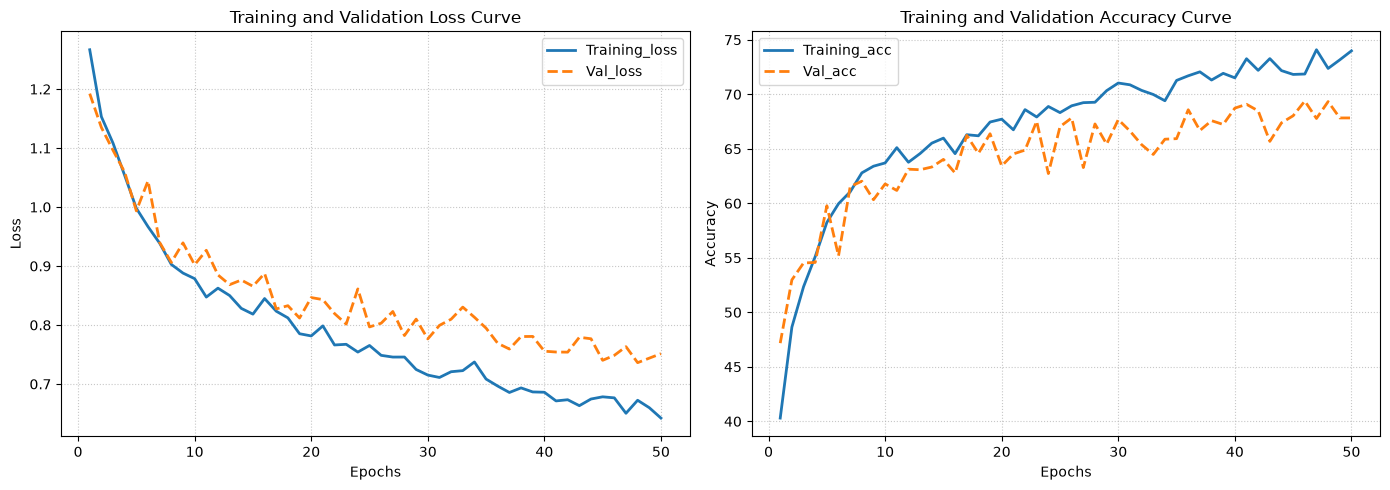

In [ ]:
## training data preparation and serving
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, random_state=42, stratify=y_data
)

train_dataset = VibrationDataset(X_train, y_train)
test_dataset = VibrationDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = DronePropeller1DCNN(
    model_variant=model_variant,
    in_channels=X_data.shape[1],
    num_classes=num_classes,
).to(device)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

## training loop
def train_and_evaluate(train_loader, test_loader, device, epochs):
    print(f"\n--- Initialized 1D CNN Model {model_variant} ---")
    print(f"Total Learnable Parameters: {count_parameters(model)} | Device: {device}")
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = loss_fn(logits, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == targets).sum().item()
            total += inputs.size(0)

        train_loss = running_loss / total
        train_acc = (correct / total) * 100.0

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                v_logits = model(inputs)
                v_loss = loss_fn(v_logits, targets)
                val_loss += v_loss.item() * inputs.size(0)
                v_preds = torch.argmax(v_logits, dim=1)
                val_correct += (v_preds == targets).sum().item()
                val_total += inputs.size(0)

        val_loss /= val_total
        val_acc = (val_correct / val_total) * 100.0

        print(
            f"Epoch {epoch}: Train_loss : {train_loss:.4f} | Val_loss: {val_loss:.4f} "
            f"| Train_accuracy: {train_acc:.4f} | Val_accuracy: {val_acc:.4f}"
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            f_logits = model(inputs)
            preds = torch.argmax(f_logits, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.cpu().numpy())

    class_names = ["F0 (Healthy)", "F1 (Edge Cut)", "F2 (Crack)", "F3 (Surface Cut)"]
    test_acc = accuracy_score(all_targets, all_preds) * 100.0

    print(f"\nFinal Test Accuracy (CNN Model {model_variant}): {test_acc:.4f}")
    print("\nPer-Class Performance (Precision, Recall, F1-Score):")
    print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))
    print("Confusion_matrix:")
    print(confusion_matrix(all_targets, all_preds))

    return model, history

## plot training and validation loss and accuracy curves
def plot_learning_curves(history):
    epoch_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epoch_range, history["train_loss"], label="Training_loss", linewidth=2)
    plt.plot(epoch_range, history["val_loss"], label="Val_loss", linewidth=2, linestyle="--")
    plt.title("Training and Validation Loss Curve")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle=":", alpha=0.7)

    plt.subplot(1, 2, 2)
    plt.plot(epoch_range, history["train_acc"], label="Training_acc", linewidth=2)
    plt.plot(epoch_range, history["val_acc"], label="Val_acc", linewidth=2, linestyle="--")
    plt.title("Training and Validation Accuracy Curve")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, linestyle=":", alpha=0.7)

    plt.tight_layout()
    plt.show()


trained_model, hist = train_and_evaluate(
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=epochs,
    device=device,
)
plot_learning_curves(history=hist)

Extracting features....
Computing t-SNE... Please wait
Plotting the clusters....


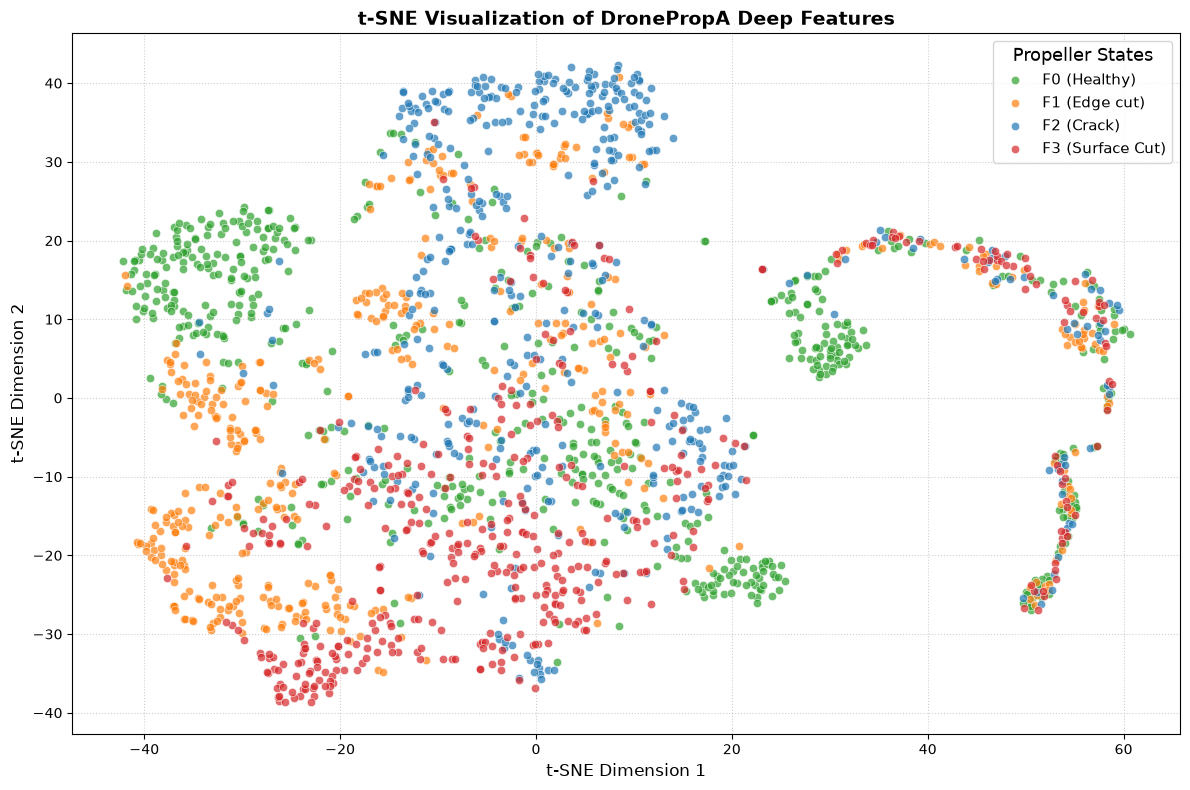

In [ ]:
## plot t-SNE clusters reduced to 2D 

def plot_tsne_clusters(model, test_loader, device):
    model.eval()
    all_features = []
    all_targets = []
    print("Extracting features....")

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            features = model.extract_features(inputs)
            all_features.append(features.cpu().numpy())
            all_targets.append(targets.numpy())

    all_features = np.concatenate(all_features, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    print("Computing t-SNE... Please wait")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    features_2d = tsne.fit_transform(all_features)

    print("Plotting the clusters....")
    plt.figure(figsize=(12, 8))
    class_names = ["F0 (Healthy)", "F1 (Edge cut)", "F2 (Crack)", "F3 (Surface Cut)"]
    colors = ["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728"]

    for class_idx, (class_name, color) in enumerate(zip(class_names, colors)):
        indices = all_targets == class_idx
        plt.scatter(
            features_2d[indices, 0],
            features_2d[indices, 1],
            c=color,
            label=class_name,
            alpha=0.7,
            edgecolors="w",
            linewidth=0.5,
        )

    plt.title("t-SNE Visualization of DronePropA Deep Features", fontsize=14, fontweight="bold")
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.legend(title="Propeller States", title_fontsize="13", fontsize="11")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


plot_tsne_clusters(trained_model, test_loader, device)

In [ ]:
## plot QDrone Data channels correlation matrix 

def plot_named_channels_correlation(signal_matrix, flight_label):
    """
    Plots a Pearson correlation heatmap for ONLY the documented drone telemetry channels
    for a single flight's data matrix
    """
    # 1. Map the MATLAB 1-based indices to their exact names
    matlab_mapping = {
        1: "Time",
        2: "Roll (IMU1)", 3: "Pitch (IMU1)", 4: "Yaw (IMU1)",
        5: "Roll Rate (IMU1)", 6: "Pitch Rate (IMU1)", 7: "Yaw Rate (IMU1)",
        8: "Roll Accel (IMU1)", 9: "Pitch Accel (IMU1)", 10: "Yaw Accel (IMU1)",
        11: "Roll (IMU2)", 12: "Pitch (IMU2)", 13: "Yaw (IMU2)",
        14: "Roll Rate (IMU2)", 15: "Pitch Rate (IMU2)", 16: "Yaw Rate (IMU2)",
        17: "Roll Accel (IMU2)", 18: "Pitch Accel (IMU2)", 19: "Yaw Accel (IMU2)",
        24: "Battery Lvl",
        27: "Roll Rate (Gyro1)", 28: "Pitch Rate (Gyro1)", 29: "Yaw Rate (Gyro1)",
        30: "Accel X (Acc1)", 31: "Accel Y (Acc1)", 32: "Accel Z (Acc1)",
        33: "Roll Rate (Gyro2)", 34: "Pitch Rate (Gyro2)", 35: "Yaw Rate (Gyro2)",
        36: "Accel X (Acc2)", 37: "Accel Y (Acc2)", 38: "Accel Z (Acc2)",
        46: "Height Range",
        47: "FL Motor Cmd", 48: "FL ESC Cmd",
        49: "FR Motor Cmd", 50: "FR ESC Cmd",
        51: "BL Motor Cmd", 52: "BL ESC Cmd",
        53: "BR Motor Cmd", 54: "BR ESC Cmd"
    }
    
    # 2. Extract the Python 0-based indices and labels
    python_indices = [k - 1 for k in matlab_mapping.keys()]
    channel_labels = list(matlab_mapping.values())
    
    # 3. Filter the (56, N) matrix down to a (41, N) matrix
    filtered_matrix = signal_matrix[python_indices, :]
    
    # 4. Create the correlation DataFrame
    df = pd.DataFrame(filtered_matrix.T, columns=channel_labels)
    corr_matrix = df.corr(method='pearson')
    
    plt.figure(figsize=(16, 14), dpi=300)
    
    sns.heatmap(
        corr_matrix, 
        annot=False,         
        cmap="coolwarm", 
        vmin=-1, 
        vmax=1, 
        square=True, 
        linewidths=0.5,      
        cbar_kws={"shrink": .8}
    )
    
    plt.title(f"Pearson Correlation - Named Channels ({flight_label})", fontsize=18, pad=20)
    plt.xticks(rotation=90, ha='center', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    
    
    plt.show()

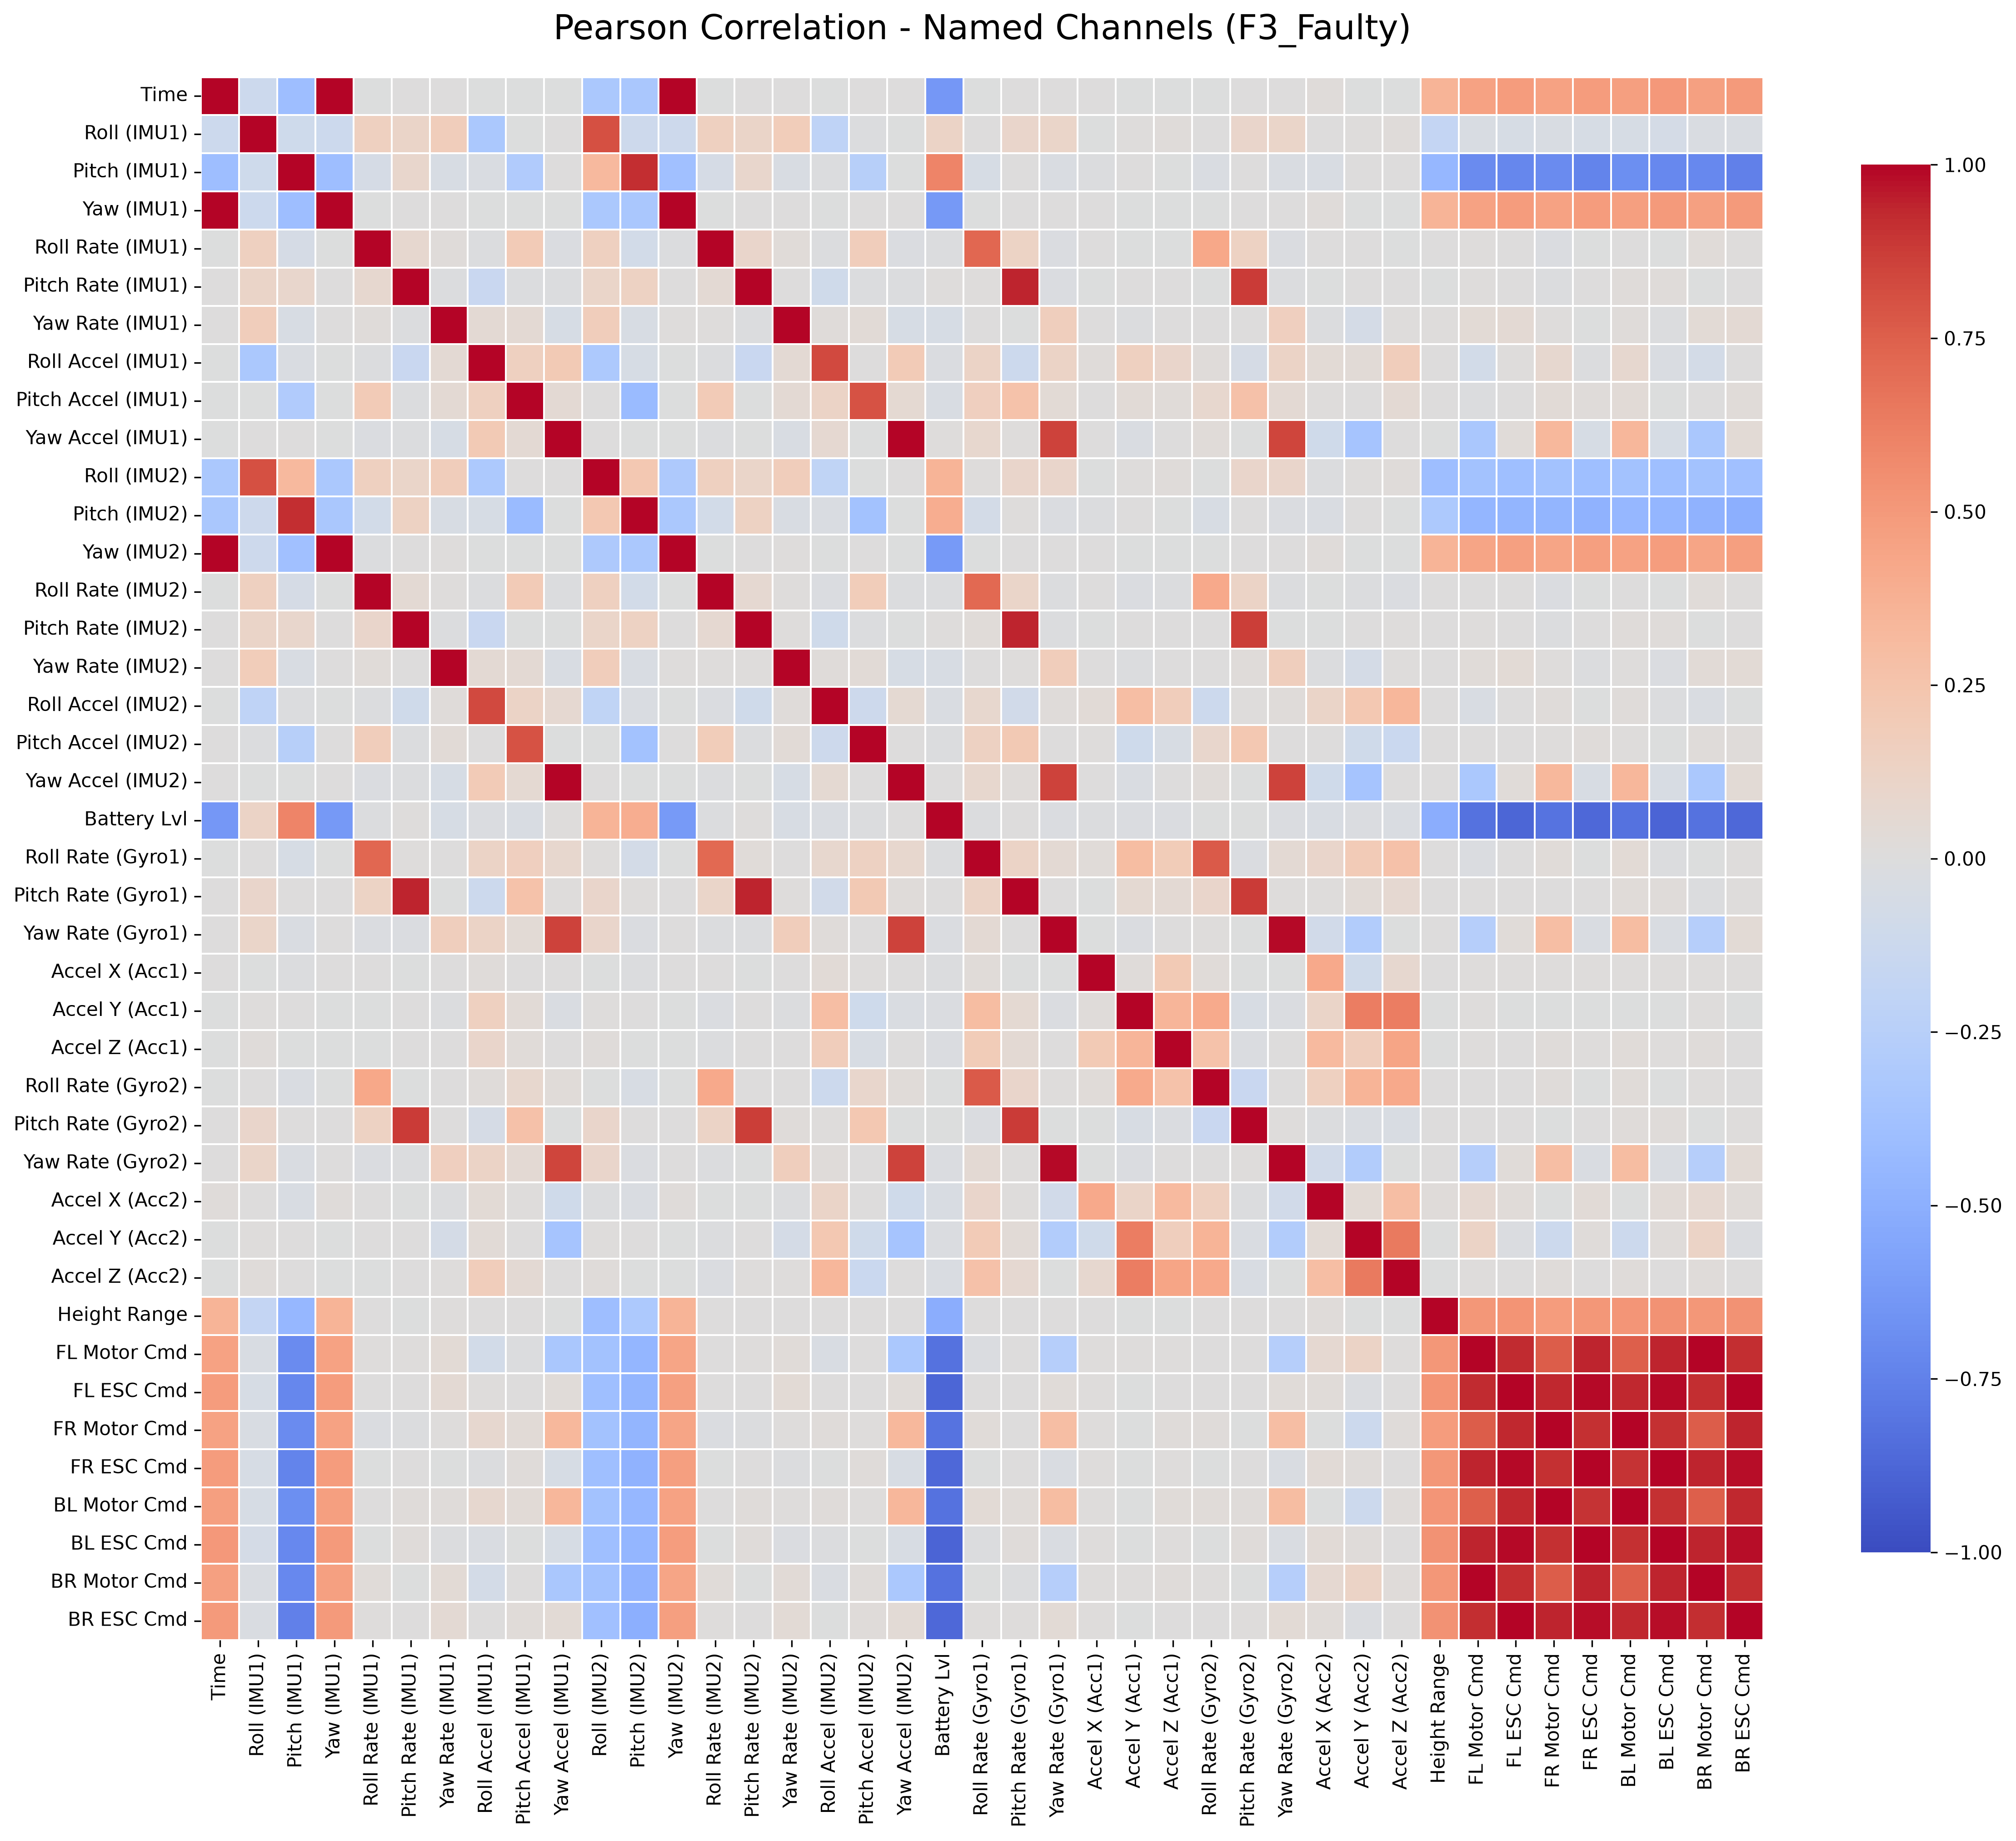

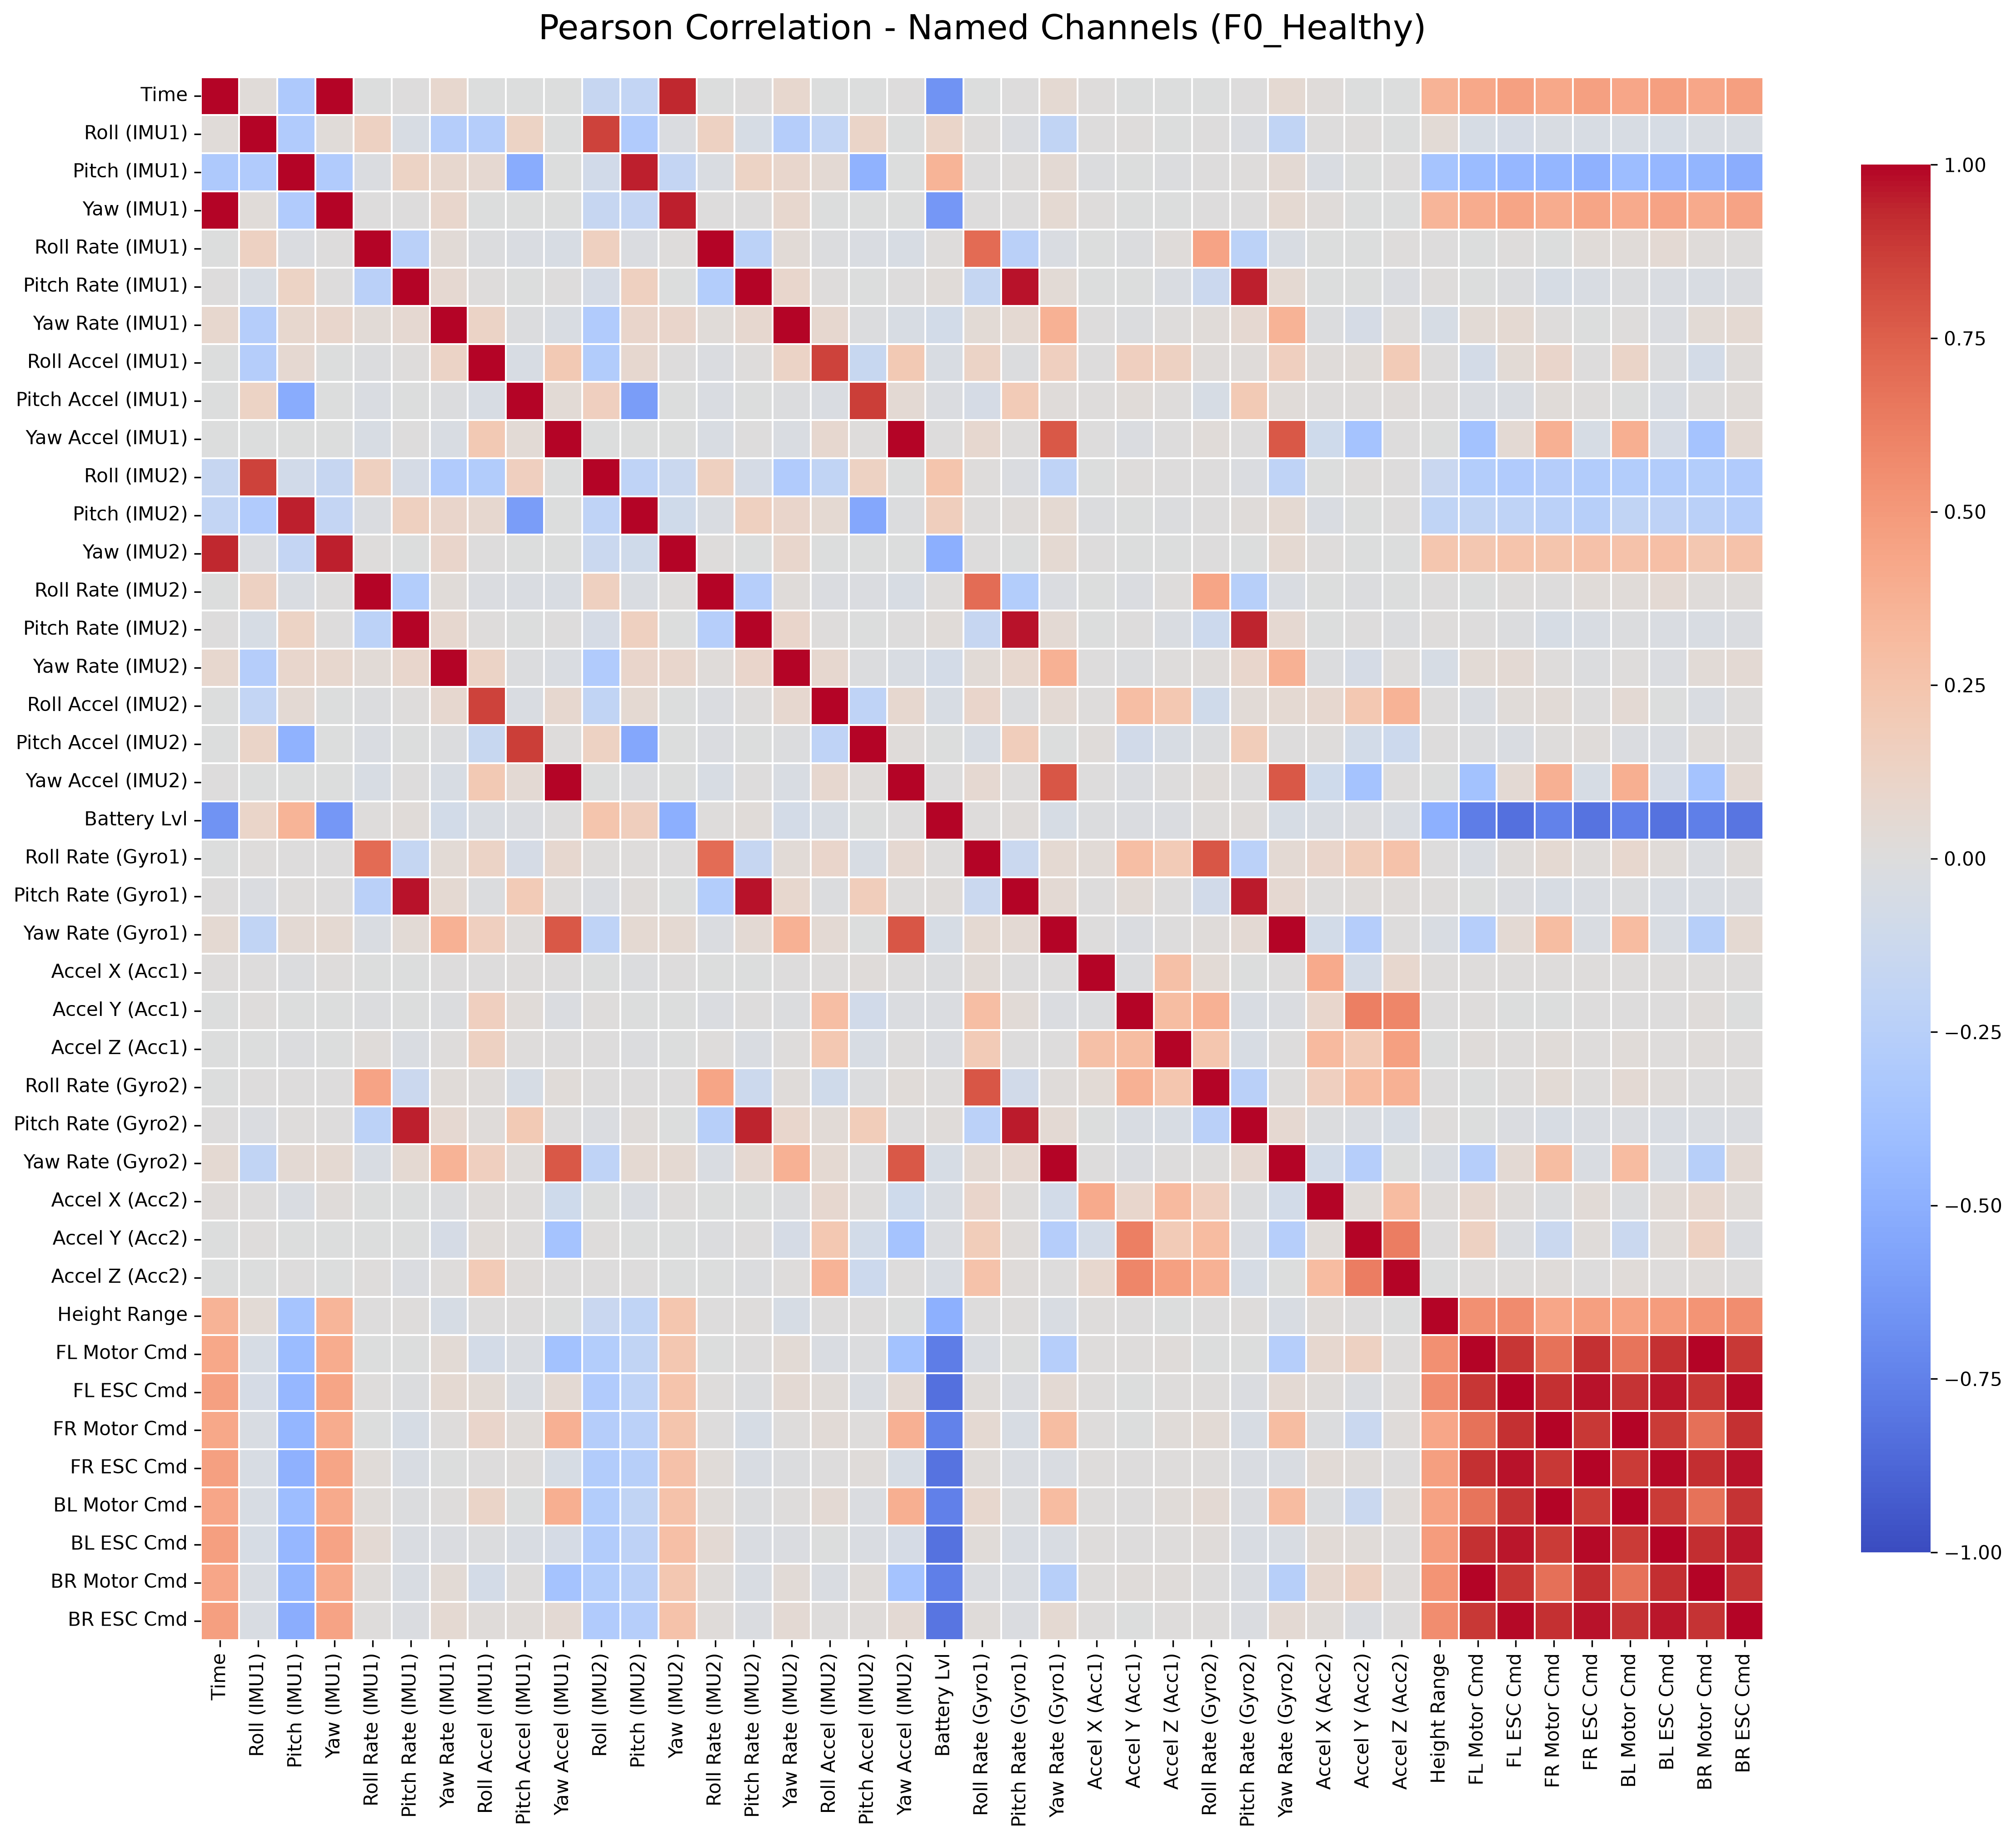

In [ ]:
data1 = sio.loadmat(r"./data")
mat1 = data1['QDrone_data']
mat1
data2 = sio.loadmat(r"./data")
mat2 = data2['QDrone_data']
plot_named_channels_correlation(mat1, "F3_Faulty")
plot_named_channels_correlation(mat2, "F0_Healthy")

In [ ]:
## plot confusion matrix and classification report in graphical form

def plot_colorful_metrics(y_true, y_pred):
    class_names = ["F0 (Healthy)", "F1 (Edge Cut)", "F2 (Crack)", "F3 (Surface Cut)"]

    # confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6), dpi=300)

    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                square=True, linewidths=0.5, cbar_kws={"shrink": .8})
    
    plt.title('Confusion Matrix - Dual-Branch TF-CNN', fontsize=16, pad=15)
    plt.xlabel('Predicted Fault Class', fontsize=12)
    plt.ylabel('True Fault Class', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # classification report
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()
    
    # Separate the 0-1 metrics from the massive 'support' values to protect the color scale
    df_metrics = df_report.drop('support', axis=1)
    
    plt.figure(figsize=(8, 6), dpi=300)
    # vmin=0.0 and vmax=1.0 strictly lock the color scale to standard percentage bounds
    sns.heatmap(df_metrics, annot=True, fmt='.4f', cmap='viridis', 
                vmin=0.0, vmax=1.0, square=True, linewidths=0.5, cbar_kws={"shrink": .8})
    
    plt.title('Classification Report Metrics', fontsize=16, pad=15)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.show()


Running quick inference to extract predictions...


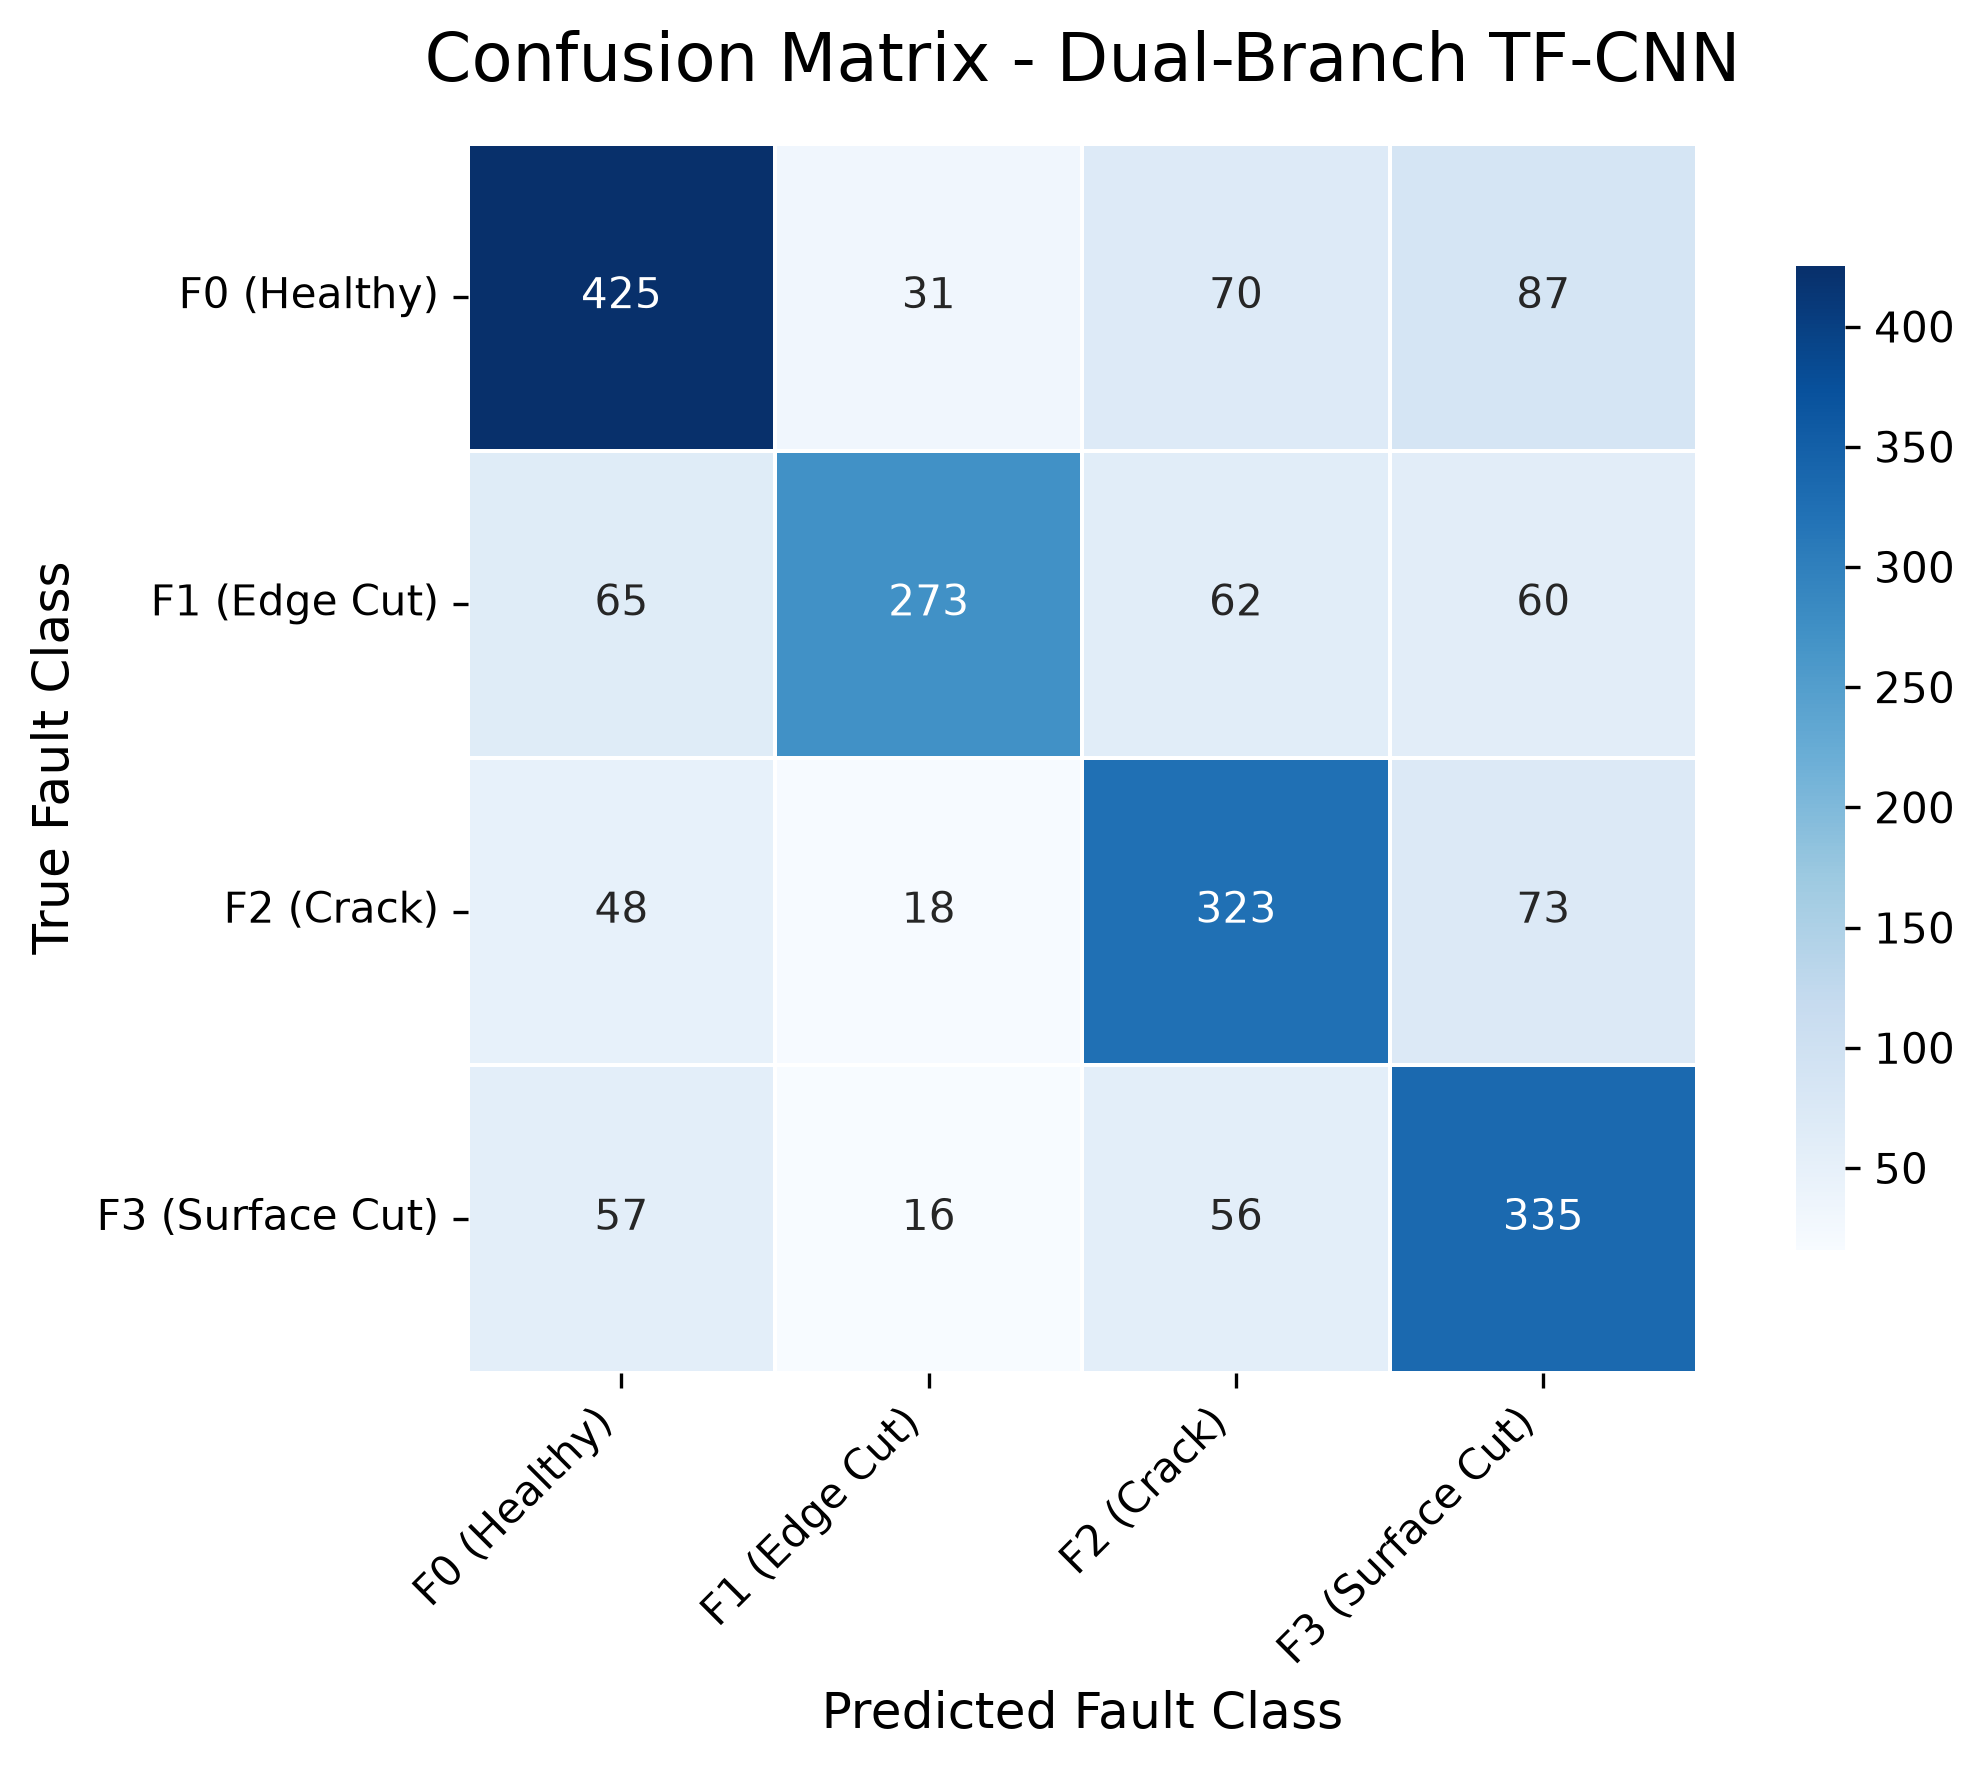

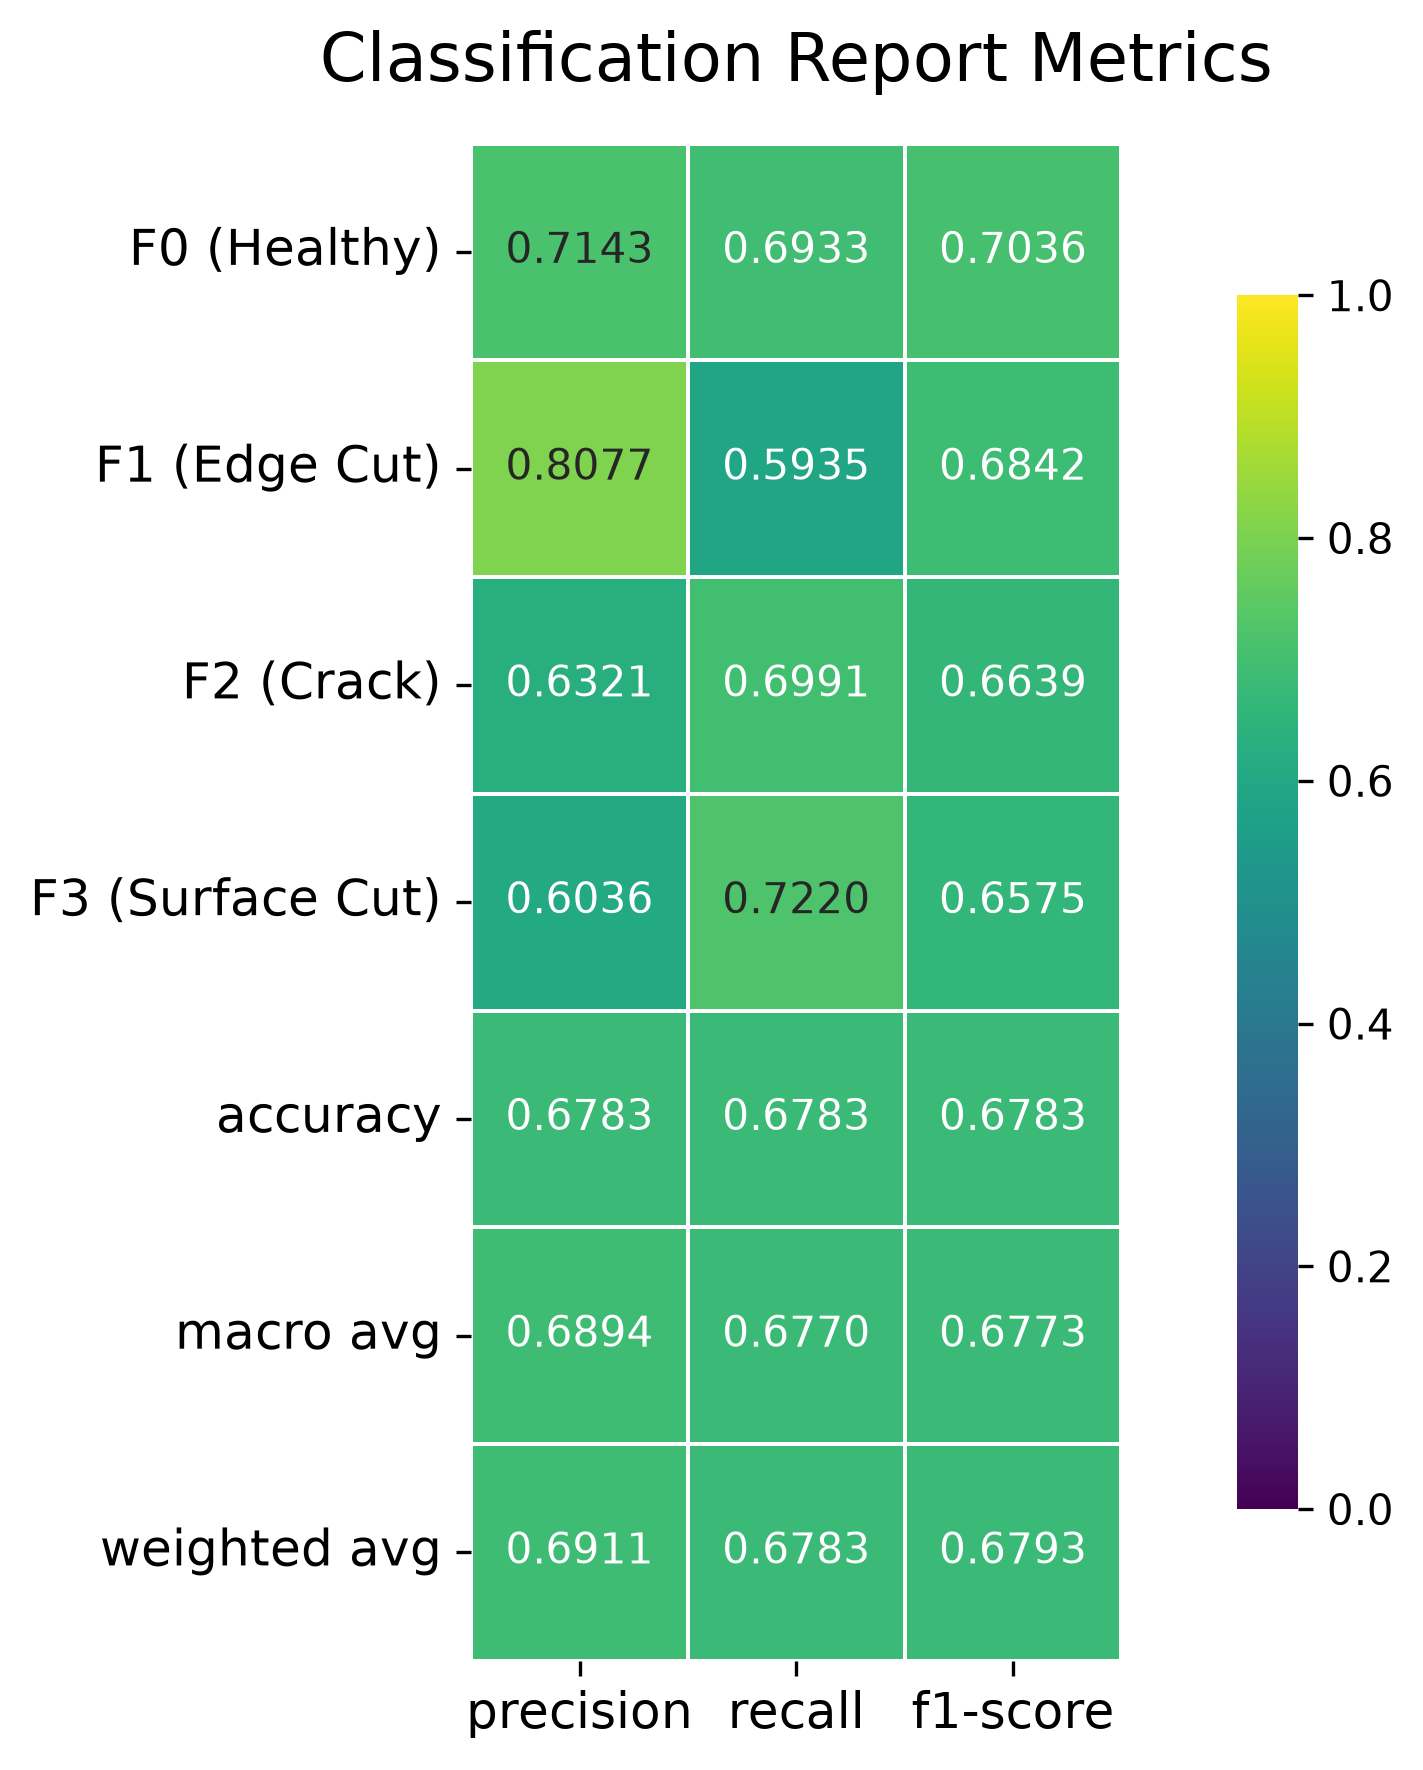

In [12]:
def get_test_predictions(model, test_loader, device):
    print("Running quick inference to extract predictions...")
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            
            # Forward pass only
            logits = model(inputs)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    return np.array(all_targets), np.array(all_preds)

# 1. Grab the predictions using your already-trained model
y_true, y_pred = get_test_predictions(trained_model, test_loader, device)

# 2. Feed them directly into the plotting function
plot_colorful_metrics(y_true, y_pred)